# Prototipe Pemodelan Awal (Spark MLlib) - Kelompok 07
**Mahadata (IF25-40402) | Minggu 10**

Klasifikasi kategori kualitas udara (AQI, PM2.5, standar EPA) per jam pada dua titik di Malaysia
(Taman Tun Dr. Ismail dan Tambulaung), data OpenAQ 1 Jan - 28 Okt 2026.

| Item | Isi |
|---|---|
| Jenis tugas | Klasifikasi multikelas |
| Target | `label` = kategori AQI dari PM2.5 jam t (0 Baik ... 4 Sangat tidak sehat) |
| Model | Logistic Regression (multinomial) dan SVM linear (`OneVsRest(LinearSVC)`) |
| Split | Berdasarkan waktu: latih Jan-Agu, uji Sep-Okt 2026 |
| Catatan | MLlib tidak punya SVM kernel RBF, sehingga prototipe memakai SVM linear. |

**Isi notebook:** baca Parquet hasil persiapan data, split waktu, bobot kelas, pipeline MLlib,
latih dan simpan model, evaluasi (accuracy, precision, recall, F1, macro-F1), confusion matrix, dan analisis kesalahan.

## 0. Setup

In [1]:
import time
import numpy as np
import pandas as pd
from pyspark.sql import SparkSession, functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression, LinearSVC, OneVsRest

SEED = 42   # dicatat sebagai dokumentasi; split berdasarkan waktu, jadi tidak ada pengacakan

CLEAN     = "hdfs://namenode:9000/openaq/clean/aqi_fitur"
MODEL_DIR = "hdfs://namenode:9000/openaq/models"

spark = (SparkSession.builder
         .appName("AQI_MLlib_Prototype")
         .config("spark.sql.session.timeZone", "UTC")
         .config("spark.sql.shuffle.partitions", "8")
         .getOrCreate())
spark.sparkContext.setLogLevel("WARN")
print("Spark", spark.version)

Spark 4.2.1


## 1. Baca data siap model (hasil notebook persiapan data)

In [ ]:
FITUR = ["pm25_lag1", "pm25_lag2", "pm25_lag3", "pm25_ma3",
         "pm1_lag1", "um003_lag1", "temperature_lag1", "relativehumidity_lag1",
         "jam_sin", "jam_cos", "is_ttdi"]

# Pengaman anti data leakage: PM2.5 jam yang sama tidak boleh jadi fitur
assert "pm25" not in FITUR
assert all(c in spark.read.parquet(CLEAN).columns for c in FITUR + ["label", "ts_local"])

data = spark.read.parquet(CLEAN).cache()
print("jumlah baris:", data.count())
data.printSchema()
data.show(5, truncate=False)

jumlah baris: 13135
root
 |-- location_name: string (nullable = true)
 |-- ts: timestamp (nullable = true)
 |-- ts_local: timestamp (nullable = true)
 |-- pm25: double (nullable = true)
 |-- label: double (nullable = true)
 |-- pm25_lag1: double (nullable = true)
 |-- pm25_lag2: double (nullable = true)
 |-- pm25_lag3: double (nullable = true)
 |-- pm25_ma3: double (nullable = true)
 |-- pm1_lag1: double (nullable = true)
 |-- um003_lag1: double (nullable = true)
 |-- temperature_lag1: double (nullable = true)
 |-- relativehumidity_lag1: double (nullable = true)
 |-- jam_sin: double (nullable = true)
 |-- jam_cos: double (nullable = true)
 |-- is_ttdi: double (nullable = true)

+--------------------+-------------------+-------------------+----+-----+---------+---------+---------+------------------+--------+----------+----------------+---------------------+----------------------+-------------------+-------+
|location_name       |ts                 |ts_local           |pm25|label|pm25_la

## 2. Split berdasarkan waktu
Data latih = sebelum 1 September 2026 (waktu lokal), data uji = 1 September 2026 dan sesudahnya.
Tidak diacak, karena modelnya harus meramalkan jam yang lebih baru daripada data latihnya.

In [ ]:
batas = F.lit("2026-09-01 00:00:00").cast("timestamp")
train = data.filter(F.col("ts_local") <  batas).cache()
test  = data.filter(F.col("ts_local") >= batas).cache()

n_train, n_test = train.count(), test.count()
print(f"latih: {n_train} ({n_train/(n_train+n_test):.1%}) | uji: {n_test} ({n_test/(n_train+n_test):.1%})")

print("waktu terakhir data latih :", train.agg(F.max("ts_local")).first()[0])
print("waktu pertama data uji    :", test.agg(F.min("ts_local")).first()[0])

latih: 10487 (79.8%) | uji: 2648 (20.2%)
waktu terakhir data latih : 2026-08-31 23:00:00
waktu pertama data uji    : 2026-09-01 00:00:00


In [ ]:
# Sebaran kelas latih vs uji
(train.groupBy("label").count().withColumnRenamed("count", "latih")
      .join(test.groupBy("label").count().withColumnRenamed("count", "uji"), "label", "outer")
      .orderBy("label").show())

+-----+-----+---+
|label|latih|uji|
+-----+-----+---+
|  0.0| 3080|312|
|  1.0| 4492|707|
|  2.0| 2502|688|
|  3.0|  401|742|
|  4.0|   12|199|
+-----+-----+---+



## 3. Bobot kelas
Kelas langka (misalnya "Sangat tidak sehat") hanya sedikit di data latih. Tanpa bobot, model cenderung mengabaikannya.
MLlib tidak punya `class_weight='balanced'`, jadi bobot dihitung manual dengan rumus yang sama:
`bobot = jumlah_baris_latih / (jumlah_kelas x jumlah_baris_kelas_itu)`.
Bobot hanya dipasang pada data latih.

In [5]:
cnt = train.groupBy("label").count()
K = cnt.count()
bobot = cnt.select("label", F.round(F.lit(n_train) / (K * F.col("count")), 2).alias("weight"))
bobot.orderBy("label").show()
# Nilai acuan: 0=0.68, 1=0.47, 2=0.84, 3=5.23, 4=174.78

train_w = train.join(bobot, on="label", how="left").cache()
print("baris tanpa bobot (harus 0):", train_w.filter(F.col("weight").isNull()).count())

+-----+------+
|label|weight|
+-----+------+
|  0.0|  0.68|
|  1.0|  0.47|
|  2.0|  0.84|
|  3.0|  5.23|
|  4.0|174.78|
+-----+------+

baris tanpa bobot (harus 0): 0


## 4. Pipeline dan model baseline
Pipeline = rangkaian langkah yang dijalankan berurutan, sehingga bisa diulang dari awal dengan satu perintah:

1. `VectorAssembler`: menggabungkan semua kolom fitur menjadi satu vektor
2. `StandardScaler`: menyamakan skala fitur (dihitung dari data latih saja)
3. Model: `LogisticRegression` atau `OneVsRest(LinearSVC)`

Semua parameter model memakai nilai default (tanpa tuning). Label sudah berupa angka berurutan 0-4,
jadi `StringIndexer` tidak diperlukan.

In [6]:
assembler = VectorAssembler(inputCols=FITUR, outputCol="fitur_mentah")
scaler = StandardScaler(inputCol="fitur_mentah", outputCol="features", withMean=True, withStd=True)

lr = LogisticRegression(featuresCol="features", labelCol="label",
                        weightCol="weight", family="multinomial")

svm_linear = OneVsRest(classifier=LinearSVC(featuresCol="features", labelCol="label"),
                       featuresCol="features", labelCol="label", weightCol="weight")

pipelines = {
    "lr":  Pipeline(stages=[assembler, scaler, lr]),
    "svm": Pipeline(stages=[assembler, scaler, svm_linear]),
}
NAMA = {"lr": "Logistic Regression", "svm": "SVM linear (OvR LinearSVC)"}
print("pipeline siap:", list(pipelines))

pipeline siap: ['lr', 'svm']


## 5. Latih kedua model

In [7]:
model_terlatih = {}
for kode, pipe in pipelines.items():
    t0 = time.time()
    model_terlatih[kode] = pipe.fit(train_w)
    print(f"{NAMA[kode]}: selesai dilatih dalam {time.time()-t0:.1f} detik")

Logistic Regression: selesai dilatih dalam 4.7 detik
SVM linear (OvR LinearSVC): selesai dilatih dalam 28.6 detik


## 6. Simpan model ke HDFS
Supaya bagian evaluasi bisa langsung memuat model tanpa melatih ulang.

In [8]:
for kode, model in model_terlatih.items():
    model.write().overwrite().save(f"{MODEL_DIR}/{kode}")
    print("tersimpan:", f"{MODEL_DIR}/{kode}")

tersimpan: hdfs://namenode:9000/openaq/models/lr
tersimpan: hdfs://namenode:9000/openaq/models/svm


## 7. Pemeriksaan cepat prediksi
Hanya memastikan model menghasilkan prediksi yang masuk akal. Metrik lengkap dihitung pada bagian evaluasi.

In [9]:
for kode, model in model_terlatih.items():
    pred = model.transform(test)
    print("===", NAMA[kode])
    pred.select("location_name", "ts_local", "label", "prediction").show(8, truncate=False)
    pred.groupBy("prediction").count().orderBy("prediction").show()

=== Logistic Regression
+--------------------+-------------------+-----+----------+
|location_name       |ts_local           |label|prediction|
+--------------------+-------------------+-----+----------+
|Taman Tun Dr. Ismail|2026-09-01 00:00:00|2.0  |2.0       |
|Taman Tun Dr. Ismail|2026-09-01 01:00:00|2.0  |2.0       |
|Taman Tun Dr. Ismail|2026-09-01 02:00:00|2.0  |2.0       |
|Taman Tun Dr. Ismail|2026-09-01 03:00:00|2.0  |2.0       |
|Taman Tun Dr. Ismail|2026-09-01 04:00:00|2.0  |2.0       |
|Taman Tun Dr. Ismail|2026-09-01 05:00:00|2.0  |2.0       |
|Taman Tun Dr. Ismail|2026-09-01 06:00:00|2.0  |2.0       |
|Taman Tun Dr. Ismail|2026-09-01 07:00:00|2.0  |2.0       |
+--------------------+-------------------+-----+----------+
only showing top 8 rows
+----------+-----+
|prediction|count|
+----------+-----+
|       0.0|  411|
|       1.0|  426|
|       2.0|  482|
|       3.0|  656|
|       4.0|  673|
+----------+-----+

=== SVM linear (OvR LinearSVC)
+--------------------+-------

## 8. Evaluasi
Metrik dihitung pada data **latih dan uji** untuk kedua model.
- Accuracy, precision dan recall berbobot, F1 berbobot: dari `MulticlassClassificationEvaluator`.
- **Macro-F1** dan confusion matrix dihitung dari tabel hitung (label, prediksi), karena evaluator MLlib tidak menyediakan macro-F1.
- Macro-F1 adalah rata-rata F1 semua kelas dengan bobot sama, jadi kelas langka sama pentingnya dengan kelas banyak.

Kalau kernel Jupyter sempat dimulai ulang, jalankan dulu sel Setup (bagian 0), lalu sel di bawah ini akan memuat data dan model dari HDFS sendiri.

In [10]:
from IPython.display import display
import matplotlib.pyplot as plt
from pyspark.ml import PipelineModel
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

NAMA = {"lr": "Logistic Regression", "svm": "SVM linear (OvR LinearSVC)"}
NAMA_KELAS = {0: "Baik", 1: "Sedang", 2: "Tidak sehat (sensitif)", 3: "Tidak sehat", 4: "Sangat tidak sehat"}

# Muat ulang data dan model hanya kalau belum ada di memori
if "train" not in globals() or "test" not in globals():
    _data = spark.read.parquet(CLEAN)
    _batas = F.lit("2026-09-01 00:00:00").cast("timestamp")
    train = _data.filter(F.col("ts_local") <  _batas).cache()
    test  = _data.filter(F.col("ts_local") >= _batas).cache()
if "model_terlatih" not in globals():
    model_terlatih = {k: PipelineModel.load(f"{MODEL_DIR}/{k}") for k in ["lr", "svm"]}

print("latih:", train.count(), "| uji:", test.count(), "| model:", list(model_terlatih))

latih: 10487 | uji: 2648 | model: ['lr', 'svm']


In [11]:
def hitung_metrik(pred):
    pred = pred.cache()
    hasil = {}
    for nama, m in {"accuracy": "accuracy", "precision_weighted": "weightedPrecision",
                    "recall_weighted": "weightedRecall", "f1_weighted": "f1"}.items():
        hasil[nama] = MulticlassClassificationEvaluator(
            labelCol="label", predictionCol="prediction", metricName=m).evaluate(pred)

    cm = pred.groupBy("label", "prediction").count().toPandas()
    cm["label"] = cm["label"].astype(int)
    cm["prediction"] = cm["prediction"].astype(int)
    kelas = sorted(set(range(5)) | set(cm["label"]) | set(cm["prediction"]))
    mat = pd.DataFrame(0, index=kelas, columns=kelas)
    for _, r in cm.iterrows():
        mat.at[r["label"], r["prediction"]] = int(r["count"])

    per_kelas = []
    for c in kelas:
        tp = mat.at[c, c]
        fp = mat[c].sum() - tp
        fn = mat.loc[c].sum() - tp
        p = tp / (tp + fp) if (tp + fp) else 0.0
        r = tp / (tp + fn) if (tp + fn) else 0.0
        f = 2 * p * r / (p + r) if (p + r) else 0.0
        per_kelas.append({"kelas": c, "nama": NAMA_KELAS.get(c, str(c)),
                          "precision": p, "recall": r, "f1": f, "support": int(mat.loc[c].sum())})
    per_kelas = pd.DataFrame(per_kelas)
    ada = (per_kelas["support"] > 0) | (mat.sum(axis=0).values > 0)   # kelas yang muncul di label atau prediksi
    hasil["f1_macro"] = per_kelas.loc[ada, "f1"].mean()
    pred.unpersist()
    return hasil, mat, per_kelas

baris_hasil, cm_uji, laporan_uji = [], {}, {}
for kode, model in model_terlatih.items():
    for bagian, d in [("latih", train), ("uji", test)]:
        m, mat, per = hitung_metrik(model.transform(d))
        baris_hasil.append({"model": NAMA[kode], "bagian": bagian, **m})
        if bagian == "uji":
            cm_uji[kode], laporan_uji[kode] = mat, per

hasil_df = pd.DataFrame(baris_hasil).round(4)
display(hasil_df)

,model,bagian,accuracy,precision_weighted,recall_weighted,f1_weighted,f1_macro
0,Logistic Regression,latih,0.8558,0.8687,0.8558,0.8597,0.7037
1,Logistic Regression,uji,0.6711,0.7710,0.6711,0.6882,0.6669
2,SVM linear (OvR LinearSVC),latih,0.7068,0.7537,0.7068,0.7122,0.5074
3,SVM linear (OvR LinearSVC),uji,0.5261,0.6121,0.5261,0.5256,0.5330


## 9. Confusion matrix (data uji)
Baris = label asli, kolom = prediksi. Warna menunjukkan proporsi per baris (recall), angka di sel adalah jumlah jam.
Gambar disimpan sebagai PNG di folder notebook.

Confusion matrix uji: Logistic Regression


,0,1,2,3,4
0,298,10,0,0,4
1,112,337,32,8,218
2,1,77,418,107,85
3,0,2,32,533,175
4,0,0,0,8,191


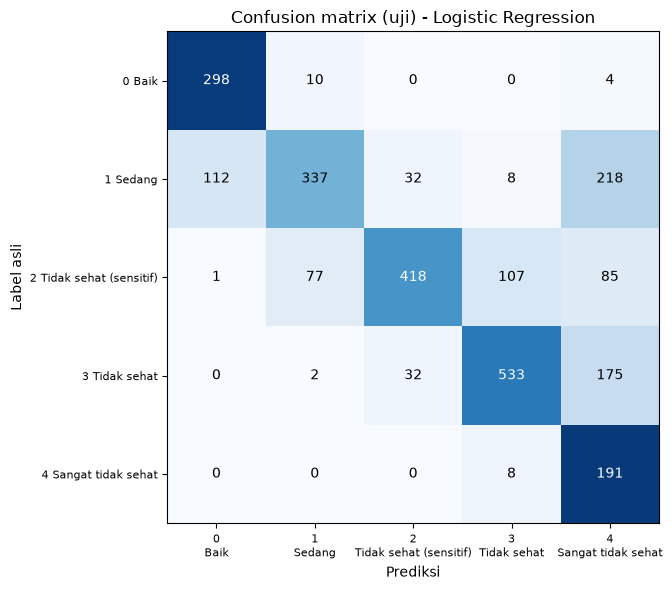

Confusion matrix uji: SVM linear (OvR LinearSVC)


,0,1,2,3,4
0,282,28,0,1,1
1,170,408,41,16,72
2,1,143,280,98,166
3,0,6,170,224,342
4,0,0,0,0,199


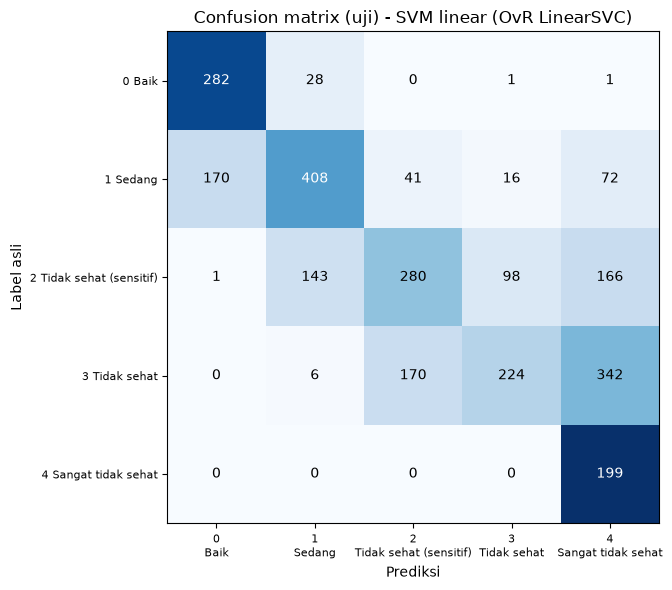

In [12]:
def gambar_cm(mat, judul, nama_file):
    kelas = list(mat.index)
    norm = mat.div(mat.sum(axis=1).replace(0, 1), axis=0)
    fig, ax = plt.subplots(figsize=(7.5, 6))
    ax.imshow(norm.values, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(kelas)))
    ax.set_yticks(range(len(kelas)))
    ax.set_xticklabels([f"{k}\n{NAMA_KELAS.get(k, '')}" for k in kelas], fontsize=8)
    ax.set_yticklabels([f"{k} {NAMA_KELAS.get(k, '')}" for k in kelas], fontsize=8)
    for i in range(len(kelas)):
        for j in range(len(kelas)):
            ax.text(j, i, str(mat.iat[i, j]), ha="center", va="center",
                    color="white" if norm.iat[i, j] > 0.5 else "black")
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Label asli")
    ax.set_title(judul)
    plt.tight_layout()
    plt.savefig(nama_file, dpi=150)
    plt.show()

for kode, mat in cm_uji.items():
    print("Confusion matrix uji:", NAMA[kode])
    display(mat)
    gambar_cm(mat, f"Confusion matrix (uji) - {NAMA[kode]}", f"confusion_matrix_{kode}.png")

## 10. Precision, recall, F1 per kelas (data uji)

In [13]:
for kode, per in laporan_uji.items():
    print("Per kelas (uji):", NAMA[kode])
    display(per.round(3))

Per kelas (uji): Logistic Regression


,kelas,nama,precision,recall,f1,support
0,0,Baik,0.725,0.955,0.824,312
1,1,Sedang,0.791,0.477,0.595,707
2,2,Tidak sehat (sensitif),0.867,0.608,0.715,688
3,3,Tidak sehat,0.812,0.718,0.763,742
4,4,Sangat tidak sehat,0.284,0.960,0.438,199


Per kelas (uji): SVM linear (OvR LinearSVC)


,kelas,nama,precision,recall,f1,support
0,0,Baik,0.623,0.904,0.737,312
1,1,Sedang,0.697,0.577,0.632,707
2,2,Tidak sehat (sensitif),0.570,0.407,0.475,688
3,3,Tidak sehat,0.661,0.302,0.414,742
4,4,Sangat tidak sehat,0.255,1.000,0.407,199


## 11. Analisis kesalahan
Lima sel di bawah menjawab: (a) kelas mana yang paling sering tertukar, (b) apakah ada beda performa per lokasi,
(c) dari mana salah tebak kelas 4 "Sangat tidak sehat" berasal, (d) seperti apa contoh kelas 4 di data latih,
(e) seberapa besar pergeseran distribusi PM2.5 antar bulan.

In [14]:
# (a) Pasangan kelas yang paling sering tertukar pada data uji
def pasangan_tertukar(mat, top=6):
    baris = []
    for i in mat.index:
        for j in mat.columns:
            if i != j and mat.at[i, j] > 0:
                baris.append({"label_asli": f"{i} {NAMA_KELAS[i]}",
                              "diprediksi": f"{j} {NAMA_KELAS[j]}",
                              "jumlah": int(mat.at[i, j]),
                              "persen_dari_kelas_asli": round(100 * mat.at[i, j] / mat.loc[i].sum(), 1)})
    return pd.DataFrame(baris).sort_values("jumlah", ascending=False).head(top)

for kode, mat in cm_uji.items():
    print("Kesalahan terbanyak (uji):", NAMA[kode])
    display(pasangan_tertukar(mat))

Kesalahan terbanyak (uji): Logistic Regression


,label_asli,diprediksi,jumlah,persen_dari_kelas_asli
5,1 Sedang,4 Sangat tidak sehat,218,30.8
12,3 Tidak sehat,4 Sangat tidak sehat,175,23.6
2,1 Sedang,0 Baik,112,15.8
8,2 Tidak sehat (sensitif),3 Tidak sehat,107,15.6
9,2 Tidak sehat (sensitif),4 Sangat tidak sehat,85,12.4
7,2 Tidak sehat (sensitif),1 Sedang,77,11.2


Kesalahan terbanyak (uji): SVM linear (OvR LinearSVC)


,label_asli,diprediksi,jumlah,persen_dari_kelas_asli
13,3 Tidak sehat,4 Sangat tidak sehat,342,46.1
3,1 Sedang,0 Baik,170,24.0
12,3 Tidak sehat,2 Tidak sehat (sensitif),170,22.9
10,2 Tidak sehat (sensitif),4 Sangat tidak sehat,166,24.1
8,2 Tidak sehat (sensitif),1 Sedang,143,20.8
9,2 Tidak sehat (sensitif),3 Tidak sehat,98,14.2


In [15]:
# (b) Akurasi per lokasi pada data uji
for kode, model in model_terlatih.items():
    pred = model.transform(test)
    print("===", NAMA[kode])
    (pred.groupBy("location_name")
         .agg(F.round(F.avg((F.col("label") == F.col("prediction")).cast("double")), 3).alias("akurasi"),
              F.count("*").alias("n"))
         .show(truncate=False))

=== Logistic Regression
+--------------------+-------+----+
|location_name       |akurasi|n   |
+--------------------+-------+----+
|Taman Tun Dr. Ismail|0.79   |1379|
|Tambulaung          |0.542  |1269|
+--------------------+-------+----+

=== SVM linear (OvR LinearSVC)
+--------------------+-------+----+
|location_name       |akurasi|n   |
+--------------------+-------+----+
|Taman Tun Dr. Ismail|0.543  |1379|
|Tambulaung          |0.507  |1269|
+--------------------+-------+----+



In [16]:
# (c) Dari mana salah tebak kelas 4 berasal (label asli per lokasi)
for kode, model in model_terlatih.items():
    pred = model.transform(test)
    print("=== Ditebak kelas 4 padahal bukan:", NAMA[kode])
    (pred.filter((F.col("prediction") == 4) & (F.col("label") != 4))
         .groupBy("location_name", "label").count()
         .orderBy("location_name", "label").show())

=== Ditebak kelas 4 padahal bukan: Logistic Regression
+--------------------+-----+-----+
|       location_name|label|count|
+--------------------+-----+-----+
|Taman Tun Dr. Ismail|  3.0|  133|
|          Tambulaung|  0.0|    4|
|          Tambulaung|  1.0|  218|
|          Tambulaung|  2.0|   85|
|          Tambulaung|  3.0|   42|
+--------------------+-----+-----+

=== Ditebak kelas 4 padahal bukan: SVM linear (OvR LinearSVC)
+--------------------+-----+-----+
|       location_name|label|count|
+--------------------+-----+-----+
|Taman Tun Dr. Ismail|  2.0|    4|
|Taman Tun Dr. Ismail|  3.0|  269|
|          Tambulaung|  0.0|    1|
|          Tambulaung|  1.0|   72|
|          Tambulaung|  2.0|  162|
|          Tambulaung|  3.0|   73|
+--------------------+-----+-----+



In [17]:
# (d) Isi kelas 4 di data latih (hanya sedikit jam)
(train.filter(F.col("label") == 4)
      .select("location_name", "ts_local", "pm25", "pm25_lag1")
      .orderBy("location_name", "ts_local")
      .show(20, truncate=False))

+--------------------+-------------------+-----+---------+
|location_name       |ts_local           |pm25 |pm25_lag1|
+--------------------+-------------------+-----+---------+
|Taman Tun Dr. Ismail|2026-02-25 03:00:00|180.0|98.3     |
|Taman Tun Dr. Ismail|2026-02-25 04:00:00|167.0|180.0    |
|Taman Tun Dr. Ismail|2026-08-26 00:00:00|126.0|120.0    |
|Taman Tun Dr. Ismail|2026-08-26 03:00:00|130.0|125.0    |
|Taman Tun Dr. Ismail|2026-08-26 04:00:00|127.0|130.0    |
|Taman Tun Dr. Ismail|2026-08-26 05:00:00|129.0|127.0    |
|Taman Tun Dr. Ismail|2026-08-26 06:00:00|130.0|129.0    |
|Tambulaung          |2026-01-03 13:00:00|202.0|21.6     |
|Tambulaung          |2026-08-23 08:00:00|157.0|22.7     |
|Tambulaung          |2026-08-31 19:00:00|132.0|125.0    |
|Tambulaung          |2026-08-31 20:00:00|133.0|132.0    |
|Tambulaung          |2026-08-31 21:00:00|130.0|133.0    |
+--------------------+-------------------+-----+---------+



In [18]:
# (e) Pergeseran distribusi: rata-rata PM2.5 per bulan per lokasi (seluruh data)
(spark.read.parquet(CLEAN)
      .withColumn("bulan", F.month("ts_local"))
      .groupBy("bulan").pivot("location_name")
      .agg(F.round(F.avg("pm25"), 1))
      .orderBy("bulan")
      .show())

+-----+--------------------+----------+
|bulan|Taman Tun Dr. Ismail|Tambulaung|
+-----+--------------------+----------+
|    1|                30.0|       4.5|
|    2|                28.2|       4.2|
|    3|                35.2|      14.3|
|    4|                36.5|      16.2|
|    5|                24.8|       3.6|
|    6|                29.0|       4.5|
|    7|                37.2|       7.2|
|    8|                48.8|      29.5|
|    9|                69.5|      40.6|
|   10|                78.3|      20.0|
+-----+--------------------+----------+

